---
title: "Лекція 2. Формалізація та нелінійна динаміка складних систем"
description: "Математичне моделювання складних систем | PhD F3 «Комп'ютерні науки» | КрНУ ім. М. Остроградського"
author: "&copy; [Valeriy Sydorenko](https://www.linkedin.com/in/valeriy-sydorenko-6782279a/), 2026"
date: today
jupyter: python3
bibliography: mmss-references.bib

format:
  html:
    code-fold: show
    code-summary: "Показати код"
    code-overflow: wrap
    toc: true
    toc-depth: 4
    toc-location: right
    number-sections: false
    embed-resources: true
    smooth-scroll: true
---

::: callout-note
## Примітка

Лекція охоплює дві нормативні теми НРП:

- *Тема 2. Концептуалізація та формалізація складних систем* -- 1 год;
- *Тема 3. Нелінійна та емерджентна динаміка складних систем* -- 1 год.

Лекція продовжує Л1 і ЛР1: від питання *«що робить систему складною?»* переходимо до двох наступних питань -- *«як перетворити уявлення про систему на досліджувану модель?»* та *«як аналізувати режими поведінки, які породжує ця модель?»*
:::

# Вступ

У Лекції 1 ми зафіксували принцип:

$$
\text{реальна система} \neq \text{модель}.
$$

Модель є цілеспрямованою абстракцією, побудованою відносно дослідницького питання. Тепер потрібно зробити наступний крок: перетворити словесне уявлення про систему на формальну конструкцію, з якою можна виконувати математичний аналіз та обчислювальний експеримент [@sayama2015; @oberkampfRoy2010].

Це породжує два взаємопов'язані ризики:

1. *помилка формалізації* -- модель математично коректна, але представляє не той механізм, який потрібний для RQ;
2. *помилка інтерпретації динаміки* -- складна поведінка моделі помилково трактується як властивість реальної системи.

Тому логіка лекції:

```{mermaid}
%%{init: {'theme': 'base', 'themeVariables': {
 'fontSize': '18px',
 'fontFamily': 'Trebuchet MS, Verdana, Arial, sans-serif',
 'primaryColor': '#E8F3FF',
 'primaryBorderColor': '#3478A8',
 'secondaryColor': '#FFF0C9',
 'tertiaryColor': '#E7F6EC',
 'lineColor': '#536878'
}}}%%
flowchart LR
  R("Реальна система") --> C("Концептуалізація")
  C --> F("Формалізація")
  F --> M("Математична модель")
  M --> D("Аналіз динаміки")
  D --> I("Інтерпретація")
  I -.->|"перегляд припущень"| C
```

# Тема 2. Концептуалізація та формалізація складних систем

## 1. Чотири рівні модельного представлення

Для модельно-обчислювального дослідження корисно розрізняти чотири рівні:

$$
\boxed{
\mathcal{S}
\rightarrow
\mathcal{C}
\rightarrow
\mathcal{M}
\rightarrow
\mathcal{K}
}
$$

де:

- $\mathcal{S}$ -- реальна система (*real system*);
- $\mathcal{C}$ -- концептуальна модель (*conceptual model*);
- $\mathcal{M}$ -- математична модель (*mathematical model*);
- $\mathcal{K}$ -- обчислювальна модель (*computational model*).

Ці рівні не можна безпечно «стиснути» до переходу

$$
\text{об'єкт} \rightarrow \text{код}.
$$

Саме проміжні рішення визначають, *що насправді означає результат програми* [@oberkampfRoy2010].

## 2. Реальна система (real system)

Реальна система містить більше властивостей, ніж будь-яка її модель. Позначимо повний, принципово недоступний опис як $\mathcal{S}$.

Дослідник спостерігає лише певну проєкцію:

$$
D = H(\mathcal{S}) + \varepsilon,
$$

де:

- $H$ -- механізм спостереження;
- $D$ -- доступні дані;
- $\varepsilon$ -- похибка або шум спостереження.

Отже, модель будується не з «реальності як такої», а з поєднання:

$$
\text{RQ} + \text{теоретичні знання} + \text{дані} + \text{припущення}.
$$

Це важливо для складних систем: неповна спостережуваність і множинність механізмів роблять перехід від даних до структури моделі неоднозначним.

## 3. Концептуальна модель (conceptual model)

*Концептуальна модель* фіксує, які сутності, механізми та причинно значущі зв'язки ми вважаємо необхідними для відповіді на RQ.

Вона має відповісти щонайменше на питання:

- що входить до системи;
- що залишається середовищем;
- які компоненти принципово важливі;
- які взаємодії враховуються;
- які механізми породжують зміну стану;
- що спостерігається;
- що є прихованим;
- які припущення вводяться.

::: callout-important
## Ключова ідея

Концептуальна модель -- не декоративна схема перед формулами. Це *наукова гіпотеза про структуру причинно значущих механізмів системи*.
:::

## 4. Межа системи (system boundary)

Нехай універсум релевантних сутностей позначено $\Omega$. Моделювання вимагає поділу

$$
\Omega = \mathcal{S}_{in} \cup \mathcal{E},
\qquad
\mathcal{S}_{in}\cap\mathcal{E}=\varnothing,
$$

де $\mathcal{S}_{in}$ -- те, що включаємо до моделі як систему, а $\mathcal{E}$ -- середовище.

Зміна межі змінює саму постановку задачі.

Наприклад, для поширення інформації рекомендаційний алгоритм платформи можна трактувати як:

- зовнішній вплив;
- внутрішній механізм системи;
- окремого агента;
- параметризовану функцію ранжування.

Усі чотири рішення можуть бути допустимими -- але для *різних RQ*.

## 5. Змінні стану, спостережувані та латентні змінні

Нехай стан системи

$$
X(t)=
\begin{bmatrix}
x_1(t) & x_2(t) & \ldots & x_n(t)
\end{bmatrix}^{T}.
$$

*Змінна стану (state variable)* потрібна для опису еволюції моделі.

Але не кожну змінну стану можна безпосередньо виміряти. Тому розрізняємо:

$$
X(t) \xrightarrow{H} Y(t),
$$

де $Y(t)$ -- *спостережувані величини (observables)*.

Якщо частина $X(t)$ не спостерігається безпосередньо, маємо *латентні змінні (latent variables)*.

Наприклад, у моделі інформаційної поведінки:

- кількість репостів -- observable;
- «схильність користувача до поширення» -- потенційно latent;
- параметр моделі, що описує цю схильність, не слід автоматично ототожнювати з реальною психологічною властивістю.

## 6. Параметри, входи та виходи

Загальну динамічну модель можна записати як

$$
\dot X(t)=F(X(t),U(t),\Theta,t),
$$

$$
Y(t)=H(X(t),\Theta,t),
$$

де:

- $X(t)$ -- стан;
- $U(t)$ -- зовнішні входи;
- $\Theta$ -- параметри;
- $Y(t)$ -- спостережувані виходи.

Різниця між ними методологічно важлива.

Параметр $\theta$ -- не просто число у програмі. Він кодує певну властивість або механізм моделі. Якщо його неможливо зв'язати з даними або обмежити теоретично, виникає проблема ідентифікованості.

## 7. Декомпозиція та агрегування

Складну систему можна описувати через декомпозицію

$$
\mathcal{S}
\rightarrow
\{\mathcal{S}_1,\mathcal{S}_2,\ldots,\mathcal{S}_k\},
$$

або через агрегування

$$
X(t)\xrightarrow{G}Z(t),
$$

де $Z(t)$ має меншу розмірність.

Агрегування завжди є інформаційним фільтром.

Якщо

$$
G(X^{(1)})=G(X^{(2)}),
$$

це не означає

$$
X^{(1)}=X^{(2)}.
$$

Отже, дві різні мікроконфігурації можуть бути нерозрізненими на макрорівні. Саме ця проблема стане важливою для ідентифікації механізмів.

## 8. Від концептуальної до математичної моделі

Формалізація означає встановлення явної відповідності:

| Концептуальне поняття | Математичний об'єкт |
|---|---|
| компонент | індекс, вузол, агент, підсистема |
| стан | змінна або вектор $X$ |
| взаємодія | функція, ребро, матриця, оператор |
| механізм | член рівняння / правило переходу |
| середовище | $U(t)$ |
| параметр | $\Theta$ |
| спостереження | $Y=H(X,\Theta)$ |
| невизначеність | випадкова змінна / розподіл / інтервал |

Формула є змістовною лише тоді, коли кожний її математичний об'єкт має модельну інтерпретацію.

## 9. Приклад: дві формалізації одного процесу

Нехай $x(t)$ -- частка активних користувачів.

### Модель A -- зовнішній вплив не враховується

$$
\frac{dx}{dt}=\beta x(1-x)-\gamma x.
$$

### Модель B -- зовнішній вплив враховується

$$
\frac{dx}{dt}=\beta x(1-x)-\gamma x+u(1-x).
$$

Це не просто «та сама модель із додатковим параметром».

Модель B містить іншу причинну гіпотезу:

> активність може виникати не лише через внутрішні взаємодії, а й через зовнішнє середовище.

Отже, зміна рівняння є зміною *наукового припущення*.

## 10. Множинність моделей одного об'єкта

Для однієї системи можливе сімейство моделей

$$
\mathfrak{M}=
\{\mathcal{M}_1,\mathcal{M}_2,\ldots,\mathcal{M}_k\}.
$$

Вони можуть відрізнятися:

- рівнем опису;
- набором механізмів;
- часовою шкалою;
- стохастичністю;
- структурою взаємодій;
- кількістю параметрів;
- спостережуваними величинами.

Наукове питання полягає не в тому, яка модель «найскладніша», а в тому, чи дозволяють дані та експеримент розрізнити альтернативні механізми [@bruntonKutz2022].

## 11. Структурна ідентифікованість (structural identifiability)

Розглянемо модель

$$
Y(t)=H(X(t;\Theta),\Theta).
$$

Нехай два набори параметрів $\Theta_1$ і $\Theta_2$ породжують однаковий вихід:

$$
Y(t;\Theta_1)=Y(t;\Theta_2)
$$

для всіх доступних умов експерименту.

Якщо з цього *не випливає*

$$
\Theta_1=\Theta_2,
$$

то параметри не є структурно ідентифікованими відносно такого спостереження.

::: callout-warning
## Наслідок

Навіть ідеальні безшумні дані не врятують модель, якщо її структура принципово не дозволяє однозначно визначити параметри.

Тому питання ідентифікованості виникає **до** калібрування, а не після нього.
:::

## 12. Простий приклад неідентифікованості

Нехай спостереження задається

$$
y(t)=(a+b)t.
$$

За даними можна визначити

$$
c=a+b,
$$

але не $a$ і $b$ окремо.

Наприклад,

$$
(a,b)=(1,2),\;(2,1),\;(0.5,2.5)
$$

дають однаковий $y(t)=3t$.

Отже, проблема не в алгоритмі оптимізації. Проблема -- у структурі моделі та спостереження.

Це найпростіша ілюстрація принципу:

$$
\text{good fit} \not\Rightarrow \text{identified mechanism}.
$$

## 13. Від математичної до обчислювальної моделі

Навіть після вибору $\mathcal{M}$ потрібно побудувати $\mathcal{K}$ -- програмну реалізацію.

```{mermaid}
%%{init: {'theme': 'base', 'themeVariables': {
 'fontSize': '18px',
 'fontFamily': 'Trebuchet MS, Verdana, Arial, sans-serif',
 'primaryColor': '#E8F3FF',
 'primaryBorderColor': '#3478A8',
 'secondaryColor': '#FFF0C9',
 'tertiaryColor': '#E7F6EC',
 'lineColor': '#536878'
}}}%%
flowchart LR
  M("Математична модель") --> N("Чисельний метод")
  N --> A("Алгоритм")
  A --> C("Програмний код")
  C --> O("Обчислювальний результат")
```

Кожний перехід може породити власну похибку:

$$
\text{model discrepancy}
\neq
\text{numerical error}
\neq
\text{implementation error}.
$$

Це розрізнення стане центральним у Темі 9 про V&V [@oberkampfRoy2010].

# Тема 3. Нелінійна та емерджентна динаміка складних систем

## 14. Від структури моделі до режимів поведінки

Після формалізації виникає нове питання:

> *Які типи поведінки допускає побудована модель і як вони змінюються зі зміною параметрів та початкових умов?*

Розглянемо автономну систему

$$
\dot X=F(X;\Theta).
$$

Її дослідження не зводиться до побудови однієї траєкторії $X(t)$. Нас цікавить *простір можливих режимів* [@strogatz2015].

## 15. Фазовий простір (phase space)

*Фазовий простір (phase space)* -- простір усіх допустимих станів $X$.

Для двовимірної системи

$$
\dot x=f(x,y), \qquad
\dot y=g(x,y)
$$

кожний стан -- точка $(x,y)$, а еволюція системи -- траєкторія у фазовій площині.

Це змінює спосіб мислення:

- часовий графік показує *як змінюється змінна*;
- фазовий портрет показує *геометрію динаміки*.

Для складних систем друге часто важливіше за окрему часову реалізацію.

## 16. Рівноважні стани (equilibria)

Стан $X^*$ є рівноважним, якщо

$$
F(X^*;\Theta)=0.
$$

Для одновимірної моделі

$$
\dot x=f(x)
$$

рівноваги визначаються з

$$
f(x^*)=0.
$$

Рівновага -- це не обов'язково «бажаний» або «реалістичний» стан. Це математичний режим, у якому модель не змінює стан.

## 17. Стійкість рівноваги

Нехай

$$
x(t)=x^*+\delta(t),
$$

де $\delta$ -- мале збурення.

Лінеаризуємо:

$$
\dot\delta \approx f'(x^*)\delta.
$$

Тоді

$$
\delta(t)\approx \delta(0)e^{f'(x^*)t}.
$$

Отже:

- якщо $f'(x^*)<0$ -- мале збурення затухає;
- якщо $f'(x^*)>0$ -- збурення зростає.

Для багатовимірної системи використовують якобіан

$$
J(X^*)=
\left[
\frac{\partial f_i}{\partial x_j}
\right]_{X=X^*},
$$

а локальна стійкість визначається власними значеннями $J$ [@strogatz2015].

## 18. Приклад: рівноваги логістичної моделі

Розглянемо

$$
\dot x = r x\left(1-\frac{x}{K}\right),
\qquad r>0,\;K>0.
$$

Рівноваги:

$$
r x\left(1-\frac{x}{K}\right)=0,
$$

тому

$$
x_1^*=0,
\qquad
x_2^*=K.
$$

Похідна

$$
f'(x)=r-\frac{2r}{K}x.
$$

Для $x_1^*=0$:

$$
f'(0)=r>0,
$$

тобто рівновага нестійка.

Для $x_2^*=K$:

$$
f'(K)=-r<0,
$$

тобто рівновага локально стійка.

Таким чином, навіть до чисельного моделювання ми вже отримали якісне знання про структуру динаміки.

## 19. Атрактори (attractors)

*Атрактор (attractor)* -- множина станів, до якої прямують траєкторії з певної області початкових умов.

Атрактором може бути:

- стійка рівновага;
- граничний цикл;
- квазіперіодичний режим;
- дивний атрактор (*strange attractor*).

Важливе поняття -- *басейн притягання (basin of attraction)*: множина початкових станів, що приводять до конкретного атрактора.

У системі з кількома атракторами довгострокова поведінка може залежати не лише від параметрів, а й від $X(0)$.

## 20. Біфуркації (bifurcations)

*Біфуркація (bifurcation)* -- якісна зміна структури динаміки при зміні параметра.

Схематично:

$$
\Theta < \Theta_c
\quad\longrightarrow\quad
\text{режим A},
$$

$$
\Theta > \Theta_c
\quad\longrightarrow\quad
\text{режим B}.
$$

У критичній області $\Theta_c$ мала зміна параметра може змінити:

- кількість рівноваг;
- їх стійкість;
- наявність циклів;
- структуру атракторів;
- довгостроковий режим.

Тому залежність «параметр → результат» у нелінійній системі може бути принципово нерівномірною.

## 21. Логістичне відображення як лабораторія нелінійної динаміки

Повернемося до моделі з Л1:

$$
x_{t+1}=r x_t(1-x_t).
$$

Тепер використовуємо її не просто для демонстрації «складної траєкторії», а для дослідження *зміни режимів* зі зміною $r$ [@strogatz2015; @sayama2015].

Для кожного $r$:

1. відкидаємо перехідний процес;
2. зберігаємо асимптотичні значення;
3. будуємо біфуркаційну діаграму.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

def logistic_map(r, x0=0.2, n=1000):
    """Траєкторія логістичного відображення."""
    x = np.empty(n)
    x[0] = x0

    for t in range(n - 1):
        x[t + 1] = r * x[t] * (1 - x[t])

    return x

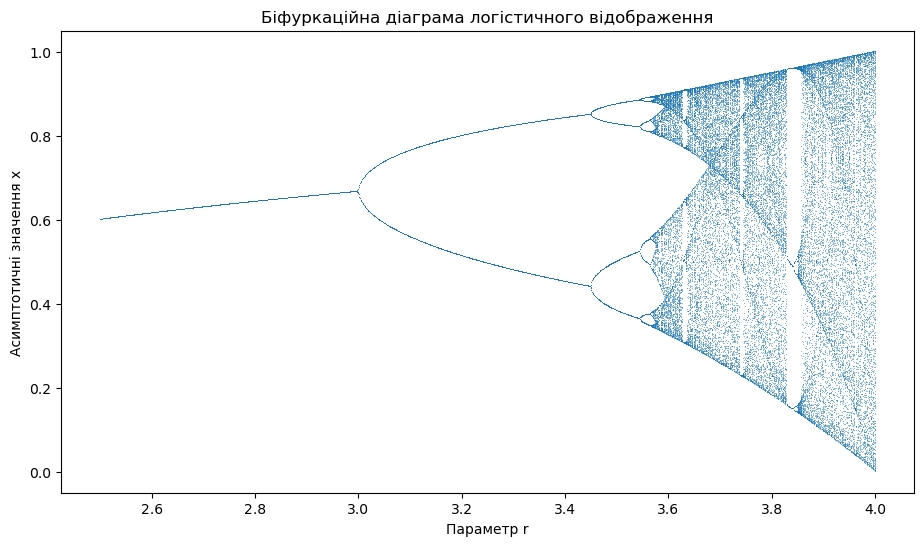

In [2]:
r_values = np.linspace(2.5, 4.0, 1200)

r_plot = []
x_plot = []

for r in r_values:
    trajectory = logistic_map(r, x0=0.2, n=1200)

    # Відкидаємо перехідний процес і залишаємо
    # лише останні значення траєкторії.
    asymptotic = trajectory[-120:]

    r_plot.extend([r] * len(asymptotic))
    x_plot.extend(asymptotic)

plt.figure(figsize=(11, 6))
plt.plot(r_plot, x_plot, ",", alpha=0.5)
plt.xlabel("Параметр r")
plt.ylabel("Асимптотичні значення x")
plt.title("Біфуркаційна діаграма логістичного відображення")
plt.show()

### Як читати біфуркаційну діаграму

Діаграма показує не одну траєкторію, а *архітектуру режимів*:

- один асимптотичний стан;
- періодичні режими;
- каскад подвоєння періоду;
- хаотичні області;
- періодичні «вікна» всередині хаотичної області.

Саме тому для нелінійної системи одного запуску моделі недостатньо.

## 22. Чутливість до початкових умов

Нехай дві траєкторії починаються з

$$
x_0
\quad\text{та}\quad
x_0+\delta_0,
$$

де $\delta_0$ дуже мале.

Для хаотичного режиму на певному часовому інтервалі характерне приблизне зростання

$$
|\delta_t|
\approx
|\delta_0|e^{\lambda t},
$$

де $\lambda>0$ -- показник Ляпунова (*Lyapunov exponent*).

Це означає:

$$
\text{детермінованість}
\not\Rightarrow
\text{довгострокова передбачуваність}.
$$

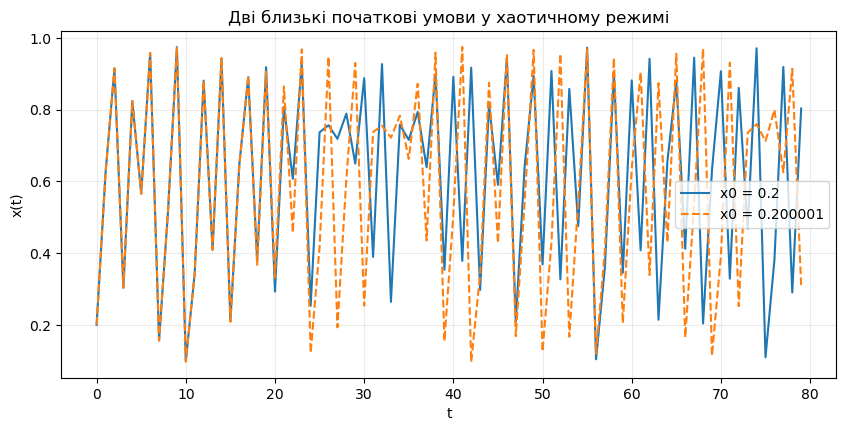

In [3]:
r = 3.9
x0_a = 0.200000
x0_b = 0.200001

xa = logistic_map(r, x0=x0_a, n=80)
xb = logistic_map(r, x0=x0_b, n=80)

plt.figure(figsize=(10, 4.5))
plt.plot(xa, label=f"x0 = {x0_a}")
plt.plot(xb, label=f"x0 = {x0_b}", linestyle="--")
plt.xlabel("t")
plt.ylabel("x(t)")
plt.title("Дві близькі початкові умови у хаотичному режимі")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

## 23. Детермінований хаос (deterministic chaos)

Хаотична система може бути повністю детермінованою:

$$
X_{t+1}=F(X_t),
$$

але демонструвати:

- аперіодичну поведінку;
- чутливість до початкових умов;
- складну геометрію атрактора;
- обмежений горизонт прогнозування.

Тому хаос не слід ототожнювати з випадковістю.

У Темі 4 ми введемо стохастичність і зможемо чітко розділити:

$$
\text{deterministic complexity}
\quad\text{vs}\quad
\text{stochastic variability}.
$$

## 24. Емерджентна динаміка

У багатокомпонентній системі макроскопічний режим може виникати з локальних правил:

$$
\{x_i(t)\}_{i=1}^{N}
+
\text{interactions}
\longrightarrow
Y_{\text{macro}}(t).
$$

При цьому $Y_{\text{macro}}$ може не бути явно закладеним у правило окремого компонента [@mitchell2009; @ladyman2013].

Приклади:

- синхронізація осциляторів;
- колективний рух;
- формування кластерів;
- каскади;
- поляризація;
- самоорганізована структура.

Але обчислювальна поява «цікавого патерну» ще не доводить emergence.

## 25. Властивість системи чи чисельний артефакт?

Нехай обчислювальна модель дає режим $R$.

Можливі щонайменше чотири пояснення:

```{mermaid}
%%{init: {'theme': 'base', 'themeVariables': {
 'fontSize': '18px',
 'fontFamily': 'Trebuchet MS, Verdana, Arial, sans-serif',
 'primaryColor': '#E8F3FF',
 'primaryBorderColor': '#3478A8',
 'secondaryColor': '#FFF0C9',
 'tertiaryColor': '#E7F6EC',
 'lineColor': '#536878'
}}}%%
flowchart TD
  R("Спостережуваний режим R")
  R --> A("Властивість<br/>математичної моделі")
  R --> B("Чисельний<br/>артефакт")
  R --> C("Помилка<br/>реалізації")
  R --> D("Властивість<br/>реальної системи?")
```

Перехід від першого пункту до останнього **не є автоматичним** [@oberkampfRoy2010].

## 26. Простий тест на чисельний артефакт

Розглянемо неперервну модель

$$
\dot x = r x(1-x).
$$

Метод Ейлера дає

$$
x_{n+1}
=
x_n
+
h r x_n(1-x_n),
$$

де $h$ -- крок інтегрування.

Тут $h$ є параметром *чисельного методу*, а не реальної системи.

Якщо зміна $h$ радикально змінює висновок, дослідник не має права автоматично інтерпретувати різницю як новий фізичний або інформаційний режим.

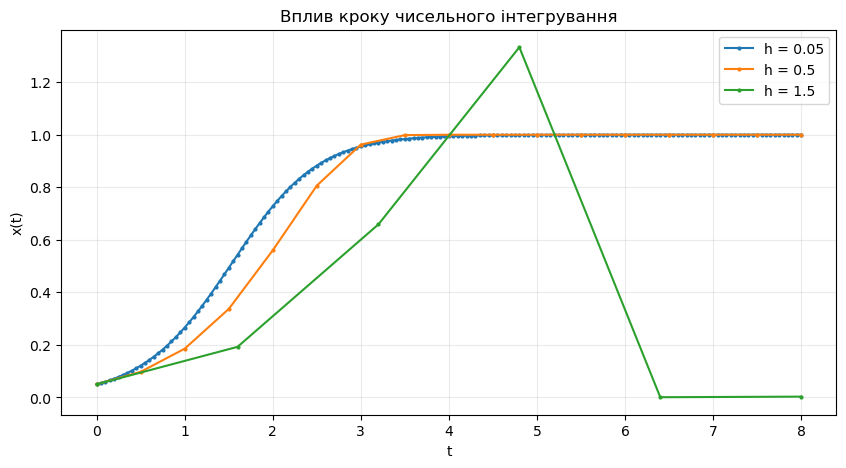

In [4]:
def euler_logistic(r, x0, h, t_end):
    """Явний метод Ейлера для dx/dt = r*x*(1-x)."""
    n = int(t_end / h) + 1
    t = np.linspace(0, t_end, n)
    x = np.empty(n)
    x[0] = x0

    for i in range(n - 1):
        x[i + 1] = x[i] + h * r * x[i] * (1 - x[i])

    return t, x

plt.figure(figsize=(10, 5))

for h in [0.05, 0.5, 1.5]:
    t, x = euler_logistic(r=2.0, x0=0.05, h=h, t_end=8)
    plt.plot(t, x, marker="o", markersize=2, label=f"h = {h}")

plt.xlabel("t")
plt.ylabel("x(t)")
plt.title("Вплив кроку чисельного інтегрування")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

::: callout-warning
## Методологічне застереження

Перед твердженням *«модель виявила новий режим»* потрібно перевірити щонайменше:

1. стійкість результату до параметрів чисельного методу;
2. відтворюваність;
3. відсутність очевидної помилки реалізації;
4. узгодженість із математичними властивостями моделі;
5. залежність від початкових умов;
6. область параметрів, у якій режим існує.

Повна процедура буде розвинена в Темі 9 -- V&V.
:::

## 27. Три різні рівні тверджень

Після симуляції важливо не змішувати:

### Рівень 1 -- твердження про код

> За цих параметрів програма породила траєкторію $X(t)$.

### Рівень 2 -- твердження про математичну модель

> Для цього класу початкових умов математична модель має режим $R$.

### Рівень 3 -- твердження про реальну систему

> У реальній системі механізм $M$ породжує режим $R$.

Кожний наступний рівень потребує додаткової доказової підтримки.

$$
\boxed{
\text{simulation output}
\not\Rightarrow
\text{model property}
\not\Rightarrow
\text{real-system property}
}
$$

# 28. Зв'язок Тем 2 і 3

На перший погляд концептуалізація та нелінійна динаміка -- різні теми. Насправді вони утворюють один дослідницький цикл:

```{mermaid}
%%{init: {'theme': 'base', 'themeVariables': {
 'fontSize': '18px',
 'fontFamily': 'Trebuchet MS, Verdana, Arial, sans-serif',
 'primaryColor': '#E8F3FF',
 'primaryBorderColor': '#3478A8',
 'secondaryColor': '#FFF0C9',
 'tertiaryColor': '#E7F6EC',
 'lineColor': '#536878'
}}}%%
flowchart LR
  Q("RQ") --> C("Концептуальна<br/>модель")
  C --> M("Математична<br/>модель")
  M --> R("Режими<br/>динаміки")
  R --> E("Пояснення<br/>механізму")
  E --> T("Перевірка<br/>припущень")
  T -.-> C
```

Неочікувана динаміка може означати нове знання -- але може також означати, що концептуальна модель, параметризація або чисельна реалізація потребують перегляду.

# 29. Перехід до ЛР2

Наступна лабораторна робота має нормативну назву:

*«Лабораторна робота 2. Дослідження нелінійної та стохастичної динаміки складної системи».*

У ній логіка ЛР1

$$
RQ \rightarrow \text{formalization} \rightarrow \text{executable model}
$$

розшириться до

$$
\text{model}
\rightarrow
\text{regimes}
\rightarrow
\text{parameter variation}
\rightarrow
\text{initial-condition sensitivity}
\rightarrow
\text{stochasticity}
\rightarrow
\text{interpretation}.
$$

Стохастичний компонент буде введено після Теми 4, але вже зараз важливо чітко розрізняти хаотичну детерміновану динаміку та випадкову мінливість.

# 30. Контрольні запитання

1. Чим концептуальна модель відрізняється від математичної?
2. Чому перехід «реальна система → код» методологічно небезпечний?
3. Як дослідницьке питання визначає межу системи?
4. У чому різниця між state variable, observable, latent variable і parameter?
5. Яку інформацію може втратити агрегування?
6. Чому дві різні моделі одного об'єкта можуть бути одночасно корисними?
7. Що означає структурна ідентифікованість?
8. Чому `good fit` не гарантує ідентифікацію механізму?
9. Що таке фазовий простір?
10. Як визначається рівноважний стан?
11. Яка ідея лежить в основі локального аналізу стійкості?
12. Що таке атрактор і басейн притягання?
13. Що змінюється під час біфуркації?
14. Чому детермінований хаос не є випадковістю?
15. Як чутливість до початкових умов обмежує прогнозування?
16. Чому не кожний патерн у симуляції можна назвати емерджентним?
17. Як відрізнити параметр моделі від параметра чисельного алгоритму?
18. Чому твердження про код, математичну модель і реальну систему мають різну доказову силу?

# Підсумкова концептуальна схема

```{mermaid}
%%{init: {'theme': 'base', 'themeVariables': {
 'fontSize': '18px',
 'fontFamily': 'Trebuchet MS, Verdana, Arial, sans-serif',
 'primaryColor': '#E8F3FF',
 'primaryBorderColor': '#3478A8',
 'secondaryColor': '#FFF0C9',
 'tertiaryColor': '#E7F6EC',
 'lineColor': '#536878'
}}}%%
flowchart LR
  S("Реальна<br/>система") --> RQ("Research<br/>Question")
  RQ --> C("Концептуальна<br/>модель")
  C --> M("Математична<br/>модель")
  M --> K("Обчислювальна<br/>модель")
  K --> D("Режими<br/>динаміки")
  D --> A("Аналіз:<br/>equilibria / stability /<br/>attractors / bifurcations")
  A --> V("Перевірка:<br/>mechanism чи artifact?")
  V --> I("Наукова<br/>інтерпретація")
  I -.->|"уточнення"| C
```

# Висновки

1. Концептуалізація визначає, *яку саме систему* ми фактично моделюємо.
2. Межа системи, рівень опису, змінні, параметри та припущення є частиною наукової постановки.
3. Формалізація встановлює явну відповідність між концептуальними механізмами та математичними об'єктами.
4. Множинність моделей одного об'єкта є нормальною; критичним є їх зв'язок із RQ та спостереженнями.
5. Структурна неідентифікованість не усувається кращим оптимізатором або більш точними даними.
6. Нелінійні моделі потрібно досліджувати як простір режимів, а не як одну траєкторію.
7. Рівноваги, стійкість, атрактори та біфуркації дають мову для опису якісної динаміки.
8. Детермінований хаос демонструє, що детермінованість не гарантує довгострокової передбачуваності.
9. Спостережуваний у симуляції режим може бути властивістю математичної моделі, чисельним артефактом або помилкою реалізації.
10. Перехід від `model output` до твердження про реальну систему потребує окремої доказової процедури.

# Джерела та корисні ресурси

Лекція використовує спільну накопичувальну бібліографічну базу курсу `mmss-references.bib`.

Додаткові відкриті ресурси:

- [Introduction to the Modeling and Analysis of Complex Systems -- Hiroki Sayama](https://milneopentextbooks.org/introduction-to-the-modeling-and-analysis-of-complex-systems/)
- [Network Science -- Albert-László Barabási](https://networksciencebook.com/)
- [SciPy documentation](https://docs.scipy.org/doc/scipy/)
- [NumPy documentation](https://numpy.org/doc/stable/)
- [Matplotlib documentation](https://matplotlib.org/stable/)

# References